In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#LOADING DATA SET

In [6]:

df = pd.read_excel("superstore .clean.xls")

('Total rown and columns in the dataset are: ', (10194, 21))

In [12]:
print("Start Date:", df["Order Date"].min())

print("End Date:", df["Order Date"].max())

Start Date: 2023-01-03 00:00:00
End Date: 2026-12-30 00:00:00


In [13]:
print("Total Sales:", df["Sales"].sum().round(1))

print("Total Profit:", df["Profit"].sum().round(1))

print("Total Quantity:", df["Quantity"].sum().round(1))

print("Average Discount:", df["Discount"].mean().round(1))

Total Sales: 2326514.8
Total Profit: 292296.8
Total Quantity: 38651.0
Average Discount: 0.2


AVARIBLE ANALYSIS

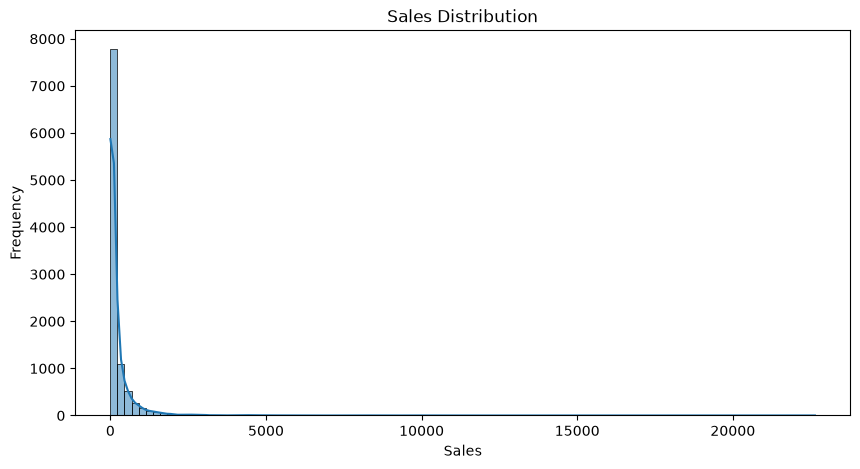

In [71]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Sales', bins=100, kde=True)
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

### 📊 Sales Distribution – Insights

- Sales distribution is highly **right-skewed**.
- Most orders have relatively low sales values.
- Only a few orders generate very high sales.
- Some extreme values indicate potential outliers.

**Conclusion:** The business receives more frequent low-value orders and fewer high-value orders.

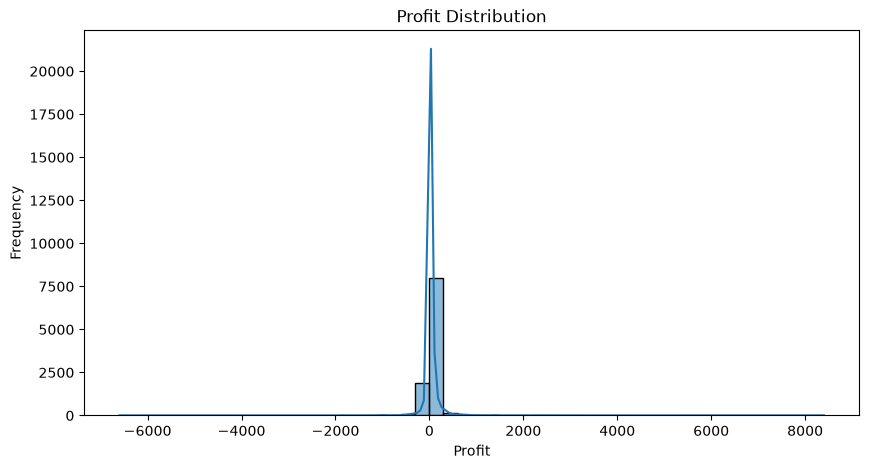

In [72]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Profit', bins=50, kde=True)
plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.show()

### 📊 Profit Distribution – Insights

- Profit distribution is highly concentrated around zero.
- Most orders generate relatively small profits.
- Some transactions result in negative profits (losses).
- A few extreme values indicate unusually high profits or losses.

**Conclusion:** Most transactions generate low profits, while some orders result in significant gains or losses.

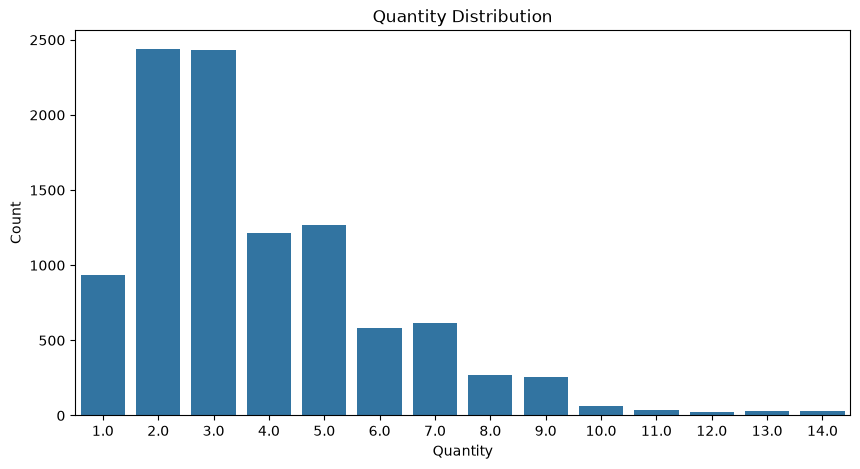

In [74]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Quantity')
plt.title('Quantity Distribution')
plt.xlabel('Quantity')
plt.ylabel('Count')
plt.show()

### 📊 Quantity Distribution – Insights

- Most orders contain **2–3 items**.
- Order frequency decreases as quantity increases.
- Bulk orders (10–14 items) are very rare.
- Customers generally prefer small-quantity purchases.

**Conclusion:** The business mainly receives small-quantity orders, with very few bulk purchases.

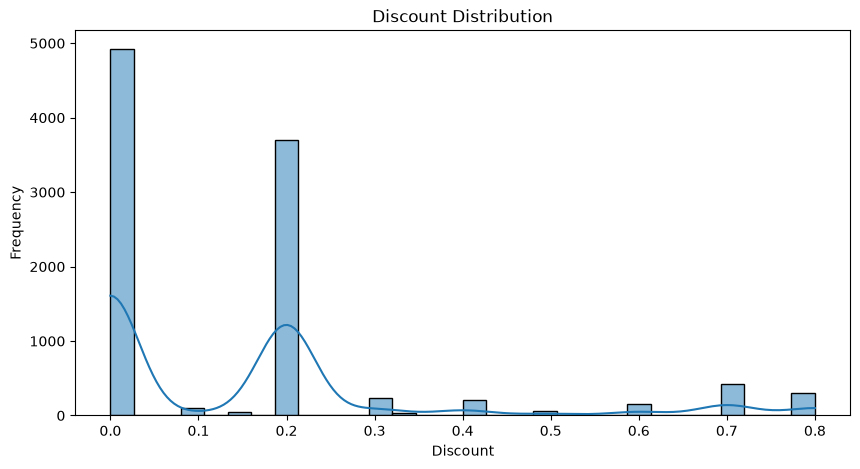

In [75]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Discount', bins=30, kde=True)
plt.title('Discount Distribution')
plt.xlabel('Discount')
plt.ylabel('Frequency')
plt.show()

### 📊 Discount Distribution – Insights

- Most orders receive **0% or 20% discounts**.
- Higher discounts (30%–80%) are less frequent.
- Some orders receive heavy discounts, which may impact profitability.
- Discount distribution is uneven across orders.

**Conclusion:** The company mainly offers 0% and 20% discounts, while higher discounts are relatively rare.

BIVARIATE ANALYSIS

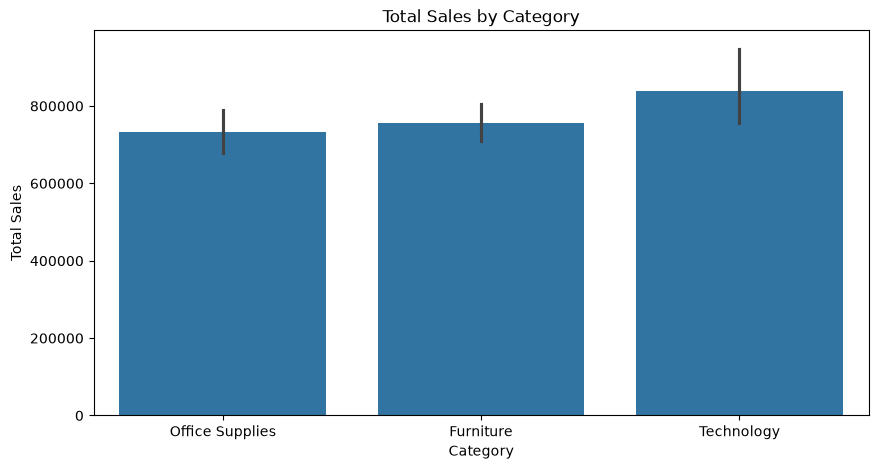

In [76]:
plt.figure(figsize=(10,5))

sns.barplot(data=df, x='Category', y='Sales', estimator='sum')

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.show()

### 📊 Total Sales by Category – Insights

- **Technology** generates the highest sales.
- **Furniture** ranks second in total sales.
- **Office Supplies** has the lowest sales.
- All three categories contribute significantly to overall revenue.

**Conclusion:** Technology is the leading sales category, making it the strongest revenue contributor.

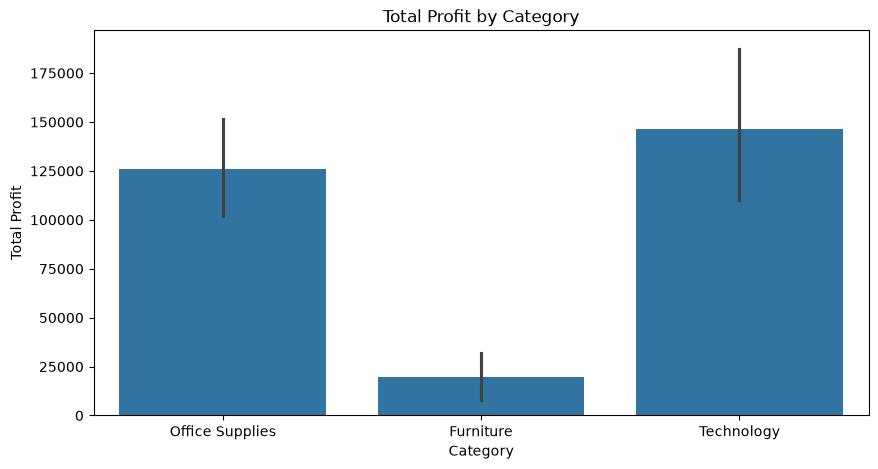

In [82]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='Category',
    y='Profit',
    estimator='sum'
)

plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.show()

### 📊 Total Profit by Category – Insights

- **Technology** generates the highest profit.
- **Office Supplies** ranks second in profitability.
- **Furniture** generates significantly lower profit.
- Furniture needs attention to improve its profitability.

**Conclusion:** Technology is the most profitable category, while Furniture has the lowest profit contribution.

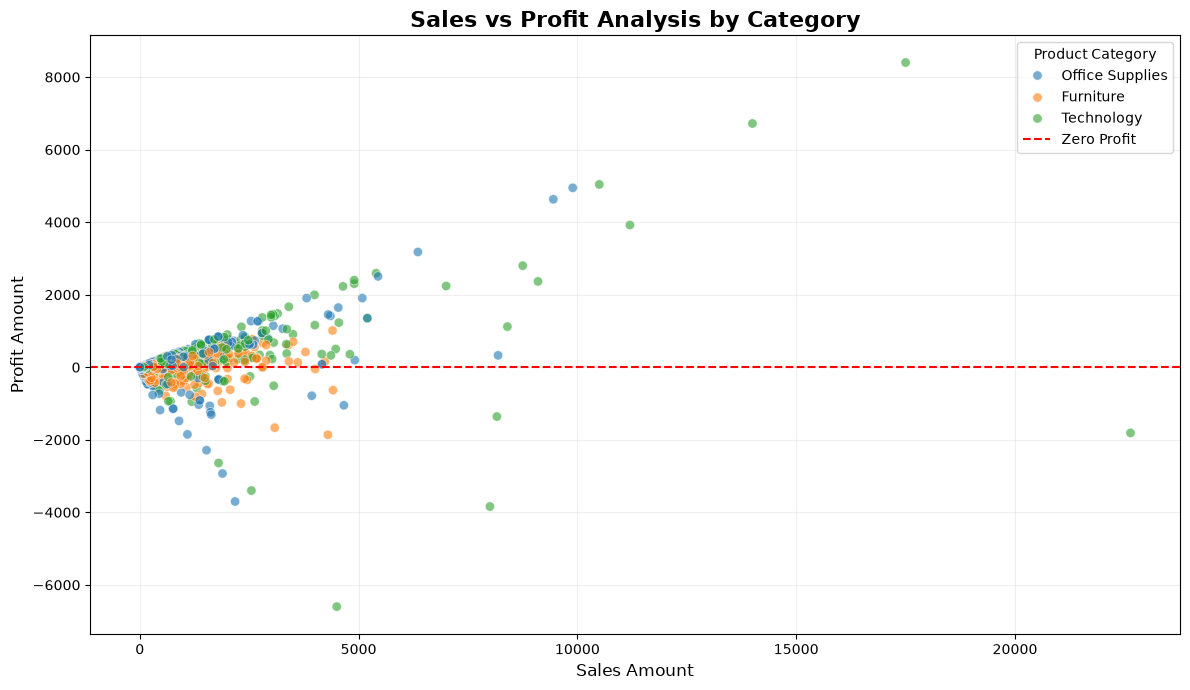

In [84]:

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category",
    alpha=0.6,
    s=45
)

# Zero profit reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Zero Profit"
)

plt.title(
    "Sales vs Profit Analysis by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales Amount", fontsize=12)
plt.ylabel("Profit Amount", fontsize=12)

plt.legend(title="Product Category")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 📊 Sales vs Profit Analysis by Category – Insights

- Sales and profit generally show a positive relationship.
- **Technology** has the highest sales and profit values.
- **Furniture** shows several loss-making transactions.
- Some high-sales orders also generate significant losses.
- Outliers indicate unusually high sales or profits/losses.

**Conclusion:** Higher sales do not always guarantee higher profit. The company should focus on improving profitability, especially in Furniture.

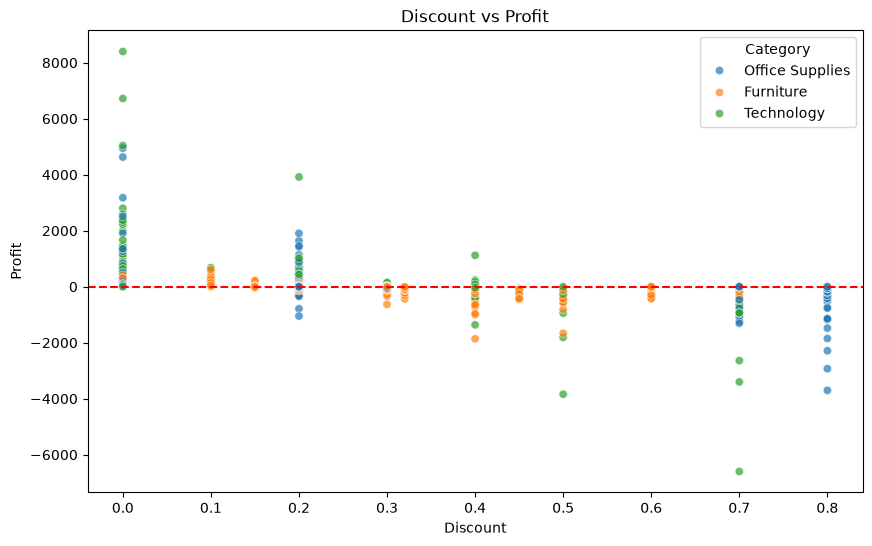

In [86]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha=0.7
)

plt.title('Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.axhline(y=0, color='red', linestyle='--')

plt.show()


### 📊 Discount vs Profit – Insights

- Higher discounts generally lead to lower profits.
- At 0% discount, many transactions generate positive profits.
- Discounts of 30%–80% show more loss-making transactions.
- High discounts can negatively impact profitability.
- Technology shows some extreme profit and loss values.

**Conclusion:** Excessive discounting can reduce profitability. The company should optimize discount strategies to maintain healthy profit margins.

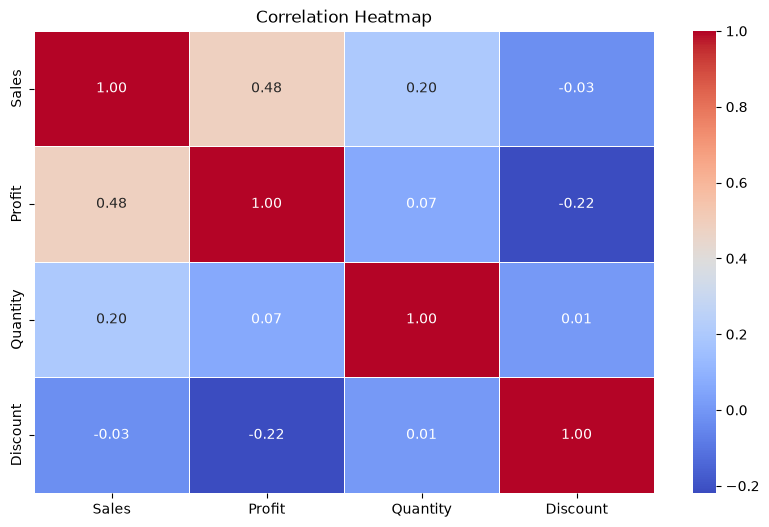

In [88]:
plt.figure(figsize=(10, 6))

corr = df[['Sales', 'Profit', 'Quantity', 'Discount']].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

### 📊 Correlation Heatmap – Insights

- Sales and Profit have a moderate positive correlation (0.48).
- Discount and Profit show a negative correlation (-0.22).
- Quantity has a weak relationship with Sales (0.20).
- Discount has almost no correlation with Sales (-0.03).
- Quantity has very little impact on Profit (0.07).

**Conclusion:** Sales positively influence Profit, while higher discounts are associated with lower profitability.

EDA - EXPLORATORY DATA ANALYSIS

In [8]:
category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

category_analysis['Profit Margin'] = (
    category_analysis['Profit'] / category_analysis['Sales']
) * 100

category_analysis

,Category,Sales,Profit,Quantity,Profit Margin
0,Furniture,754747.7613,19729.9956,8369.0,2.614118
1,Office Supplies,731873.7780,126023.4434,23265.0,17.219287
2,Technology,839893.2790,146543.3756,7017.0,17.447857


Business Insights
1. Technology: Highest Sales aur Highest Profit generate kar rahi hai.
2. Office Supplies: Sales comparatively kam hain, lekin profit achha generate kar rahi hai.
3. Furniture: Sales achhi hone ke bawajood Profit Margin sirf 2.61% hai. Is category ko improve karne ki zaroorat hai.

In [9]:
subcategory_analysis = df.groupby('Sub-Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

subcategory_analysis = subcategory_analysis.sort_values(
    by='Profit',
    ascending=False
)

subcategory_analysis

,Sub-Category,Sales,Profit,Quantity
6,Copiers,150745.2900,56093.9365,242.0
13,Phones,331842.6400,45050.8265,3357.0
0,Accessories,167380.3180,41936.6357,2976.0
12,Paper,79540.5380,34511.5070,5207.0
3,Binders,207354.8810,31426.1003,6071.0
5,Chairs,335768.2490,27223.5323,2431.0
14,Storage,224644.5540,21285.1115,3191.0
1,Appliances,108213.1850,18329.4844,1750.0
9,Furnishings,95598.1260,13891.7430,3799.0
7,Envelopes,16528.3620,6988.0247,914.0


1. Important Business Findings
Highest Profit
- Copiers: ₹56,093.94 profit — sabse zyada.
- Phones: ₹45,050.83 profit.
- Accessories: ₹41,936.64 profit.

Loss-making Categories
- Tables: ₹17,753.21 ka loss — sabse zyada.
- Bookcases: ₹3,632.07 ka loss.
- Supplies: ₹1,171.39 ka loss.

2. Business Recommendations
1. Copiers aur Phones jaise profitable products par focus karna chahiye.
2. Tables ki pricing aur discount strategy review karni chahiye.
3. Bookcases aur Supplies ke costs aur sales performance ko investigate karna chahiye.

In [8]:
region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

region_analysis = region_analysis.sort_values(
    by='Sales',
    ascending=False
)

region_analysis

,Region,Sales,Profit,Quantity
3,West,739813.6085,110798.8170,12466.0
1,East,691808.6320,94883.2603,11156.0
0,Central,503170.6728,39865.3070,8820.0
2,South,391721.9050,46749.4303,6209.0


In [9]:
segment_analysis = df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

segment_analysis = segment_analysis.round({
    'Sales': 1,
    'Profit': 1
})

segment_analysis

,Segment,Sales,Profit,Quantity
0,Consumer,1170640.3,136371.4,19841.0
1,Corporate,715806.1,94249.6,11898.0
2,Home Office,440068.4,61675.7,6912.0


Important Findings:
1. Consumer: Highest Sales aur Highest Profit generate karta hai.
2. Corporate: Second-highest performing segment hai.
3. Home Office: Sales sabse kam hain, lekin profit positive hai.

In [10]:
discount_analysis = df.groupby('Discount').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

discount_analysis = discount_analysis.round({
    'Sales': 1,
    'Profit': 1
})

discount_analysis

,Discount,Sales,Profit,Quantity
0,0.00,1105323.8,326718.6,18770.0
1,0.10,54952.5,9100.0,377.0
2,0.15,27558.5,1419.0,198.0
3,0.20,773919.9,91080.0,13853.0
4,0.30,104474.1,-10513.4,855.0
5,0.32,14493.5,-2391.1,105.0
6,0.40,116497.8,-23086.4,789.0
7,0.45,5485.0,-2493.1,45.0
8,0.50,58918.5,-20506.4,241.0
9,0.60,7105.9,-6164.3,554.0


2. Important Insights
1. 0% Discount: Sabse zyada total profit generate hua.
2. 20% Discount: Is discount level par bhi achha profit hai.
3. 30% se 80% Discount: Sabhi discount levels par total loss hua.
4. 70% Discount: Sabse zyada loss ₹40,300.6 hai.
Business Recommendation: High discounts ko review karna chahiye, especially 40%–80% range mein.

Note: Ye total profit ka comparison hai, individual orders ka nahi. Sales volume bhi alag-alag hai.

In [14]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum().reset_index()

monthly_sales['Order Date'] = monthly_sales['Order Date'].astype(str)

monthly_sales['Sales'] = monthly_sales['Sales'].round(1)

monthly_sales
monthly_sales = monthly_sales.sort_values(by='Sales', ascending=False)
monthly_sales

,Order Date,Sales
46,2026-11,118454.5
35,2025-12,97502.3
44,2026-09,88064.5
47,2026-12,85175.0
45,2026-10,83474.8
8,2023-09,82670.4
34,2025-11,79412.0
10,2023-11,78827.0
22,2024-11,75972.6
23,2024-12,75532.6


Monthly Sales Findings
1. November 2026: Highest monthly Sales — ₹118454.5
2. February 2023: Lowest monthly Sales — ₹4519.9
3. December 2025: Sales ₹97502.3 rahi.
4. Overall, 2025 aur 2026 mein sales kaafi improve hoti hui dikh rahi hain.

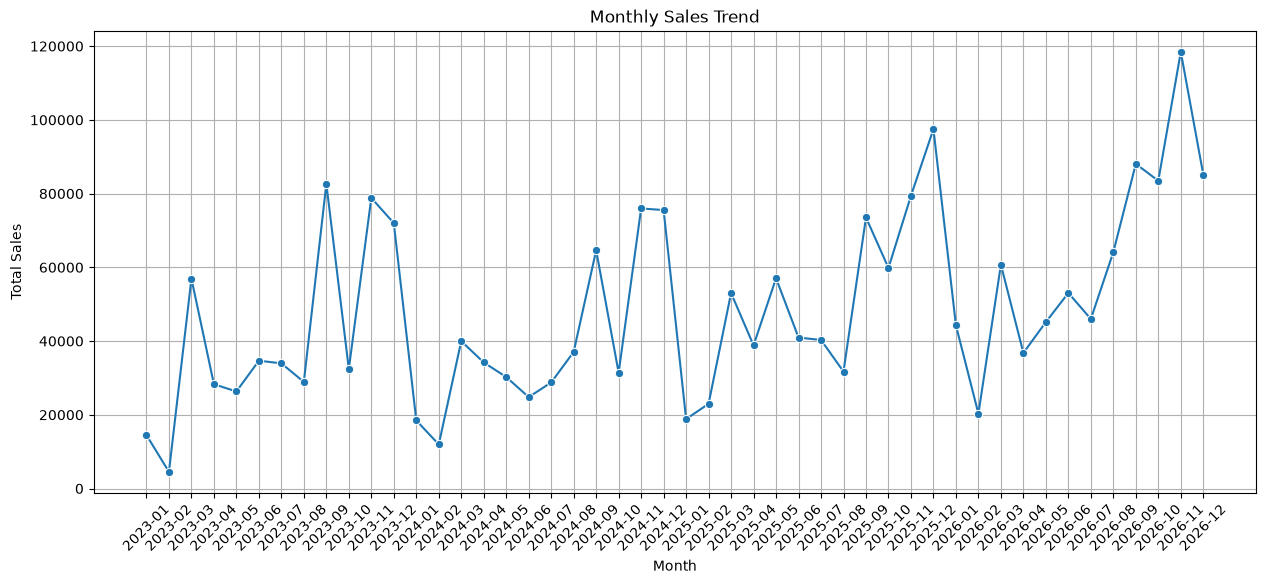

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
df['Order Date'] = pd.to_datetime(df['Order Date'])

monthly_sales2= df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum().reset_index()

monthly_sales2['Order Date'] = monthly_sales2['Order Date'].astype(str)

monthly_sales2['Sales'] = monthly_sales2['Sales'].round(1)

monthly_sales2
plt.figure(figsize=(15,6))

sns.lineplot(
    data=monthly_sales2,
    x='Order Date',
    y='Sales',
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [21]:
monthly_profit = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Profit'].sum().reset_index()

monthly_profit['Order Date'] = monthly_profit['Order Date'].astype(str)

monthly_profit['Profit'] = monthly_profit['Profit'].round(1)

monthly_profit

,Order Date,Profit
0,2023-01,2539.4
1,2023-02,862.3
2,2023-03,693.4
3,2023-04,3488.8
4,2023-05,3196.4
5,2023-06,4999.8
6,2023-07,-841.5
7,2023-08,5765.2
8,2023-09,8593.6
9,2023-10,3469.2


Monthly Profit Findings
1. December 2025: Highest Profit — ₹17926.3
2. January 2024: Lowest Profit — -₹3189.8 (Loss)
3. July 2023: Loss — -₹841.5
4. 2025 aur 2026 mein kai months mein achha profit generate hua.

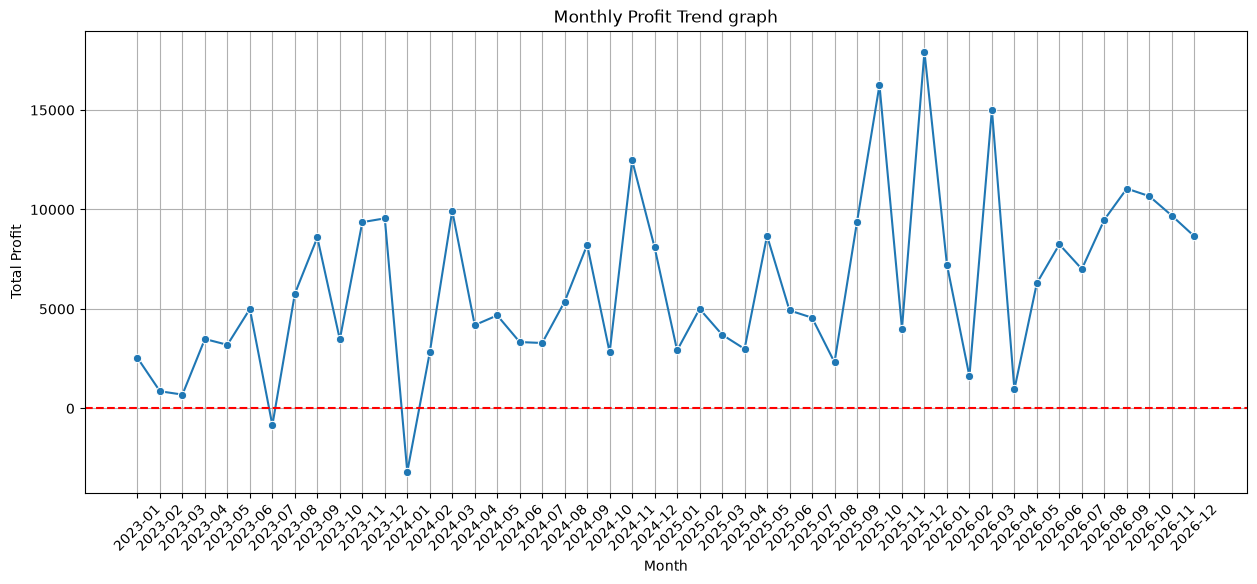

In [24]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_profit,
    x='Order Date',
    y='Profit',
    marker='o'
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Monthly Profit Trend graph')
plt.xlabel('Month')
plt.ylabel('Total Profit')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [25]:
yearly_analysis = df.groupby(
    df['Order Date'].dt.year
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

yearly_analysis = yearly_analysis.rename(
    columns={'Order Date': 'Year'}
)

yearly_analysis = yearly_analysis.round(1)

yearly_analysis

,Year,Sales,Profit
0,2023,494020.7,51684.3
1,2024,472993.0,62021.0
2,2025,613933.6,82665.2
3,2026,745567.5,95926.3


Important Insights:
1. 2026: Highest Sales aur Profit.
2. 2024: Sales mein 2023 ke comparison mein decline hua, lekin Profit increase hua.
3. 2025: Sales aur Profit dono mein achhi growth hui.
4. Overall, 2024 ke baad business ki performance improve hui.

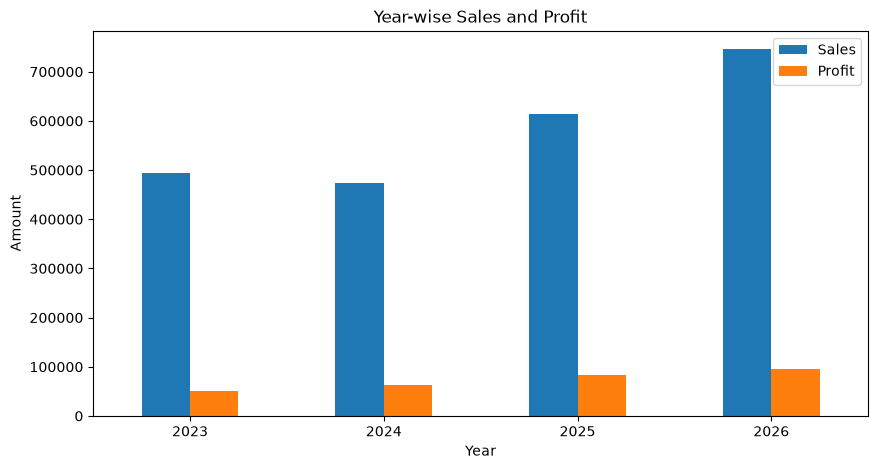

In [26]:
yearly_analysis.plot(
    x='Year',
    y=['Sales', 'Profit'],
    kind='bar',
    figsize=(10, 5)
)

plt.title('Year-wise Sales and Profit')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [29]:
top_customers = df.groupby('Customer Name').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

top_customers = top_customers.sort_values(
    by='Sales',
    ascending=False
).head(10)

top_customers = top_customers.round(1)

top_customers

,Customer Name,Sales,Profit
693,Sean Miller,25043.0,-1980.7
737,Tamara Chand,19052.2,8981.3
629,Raymond Buch,15117.3,6976.1
764,Tom Ashbrook,14595.6,4703.8
6,Adrian Barton,14473.6,5444.8
446,Ken Lonsdale,14175.2,806.9
678,Sanjit Chand,14142.3,5757.4
336,Hunter Lopez,12873.3,5622.4
679,Sanjit Engle,12209.4,2650.7
157,Christopher Conant,12129.1,2177.0


Key Insights
1. Sean Miller ki sales sabse zyada ₹25,043.0 hai, lekin profit -₹1,980.7 (loss) hai.
2. Tamara Chand ne ₹19,052.2 sales ke saath ₹8,981.3 profit kamaya — top 10 mein highest profit.
3. Raymond Buch aur Sanjit Chand bhi achha profit generate kar rahe hain.
4. High sales ka matlab hamesha high profit nahi hota. Sean Miller iska example hai.

In [30]:
top_profit_customers = df.groupby('Customer Name').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

top_profit_customers = top_profit_customers.sort_values(
    by='Profit',
    ascending=False
).head(10)

top_profit_customers = top_profit_customers.round(1)
top_profit_customers

,Customer Name,Sales,Profit
737,Tamara Chand,19052.2,8981.3
629,Raymond Buch,15117.3,6976.1
678,Sanjit Chand,14142.3,5757.4
336,Hunter Lopez,12873.3,5622.4
6,Adrian Barton,14473.6,5444.8
764,Tom Ashbrook,14595.6,4703.8
158,Christopher Martinez,8954.0,3899.9
436,Keith Dawkins,8181.3,3038.6
35,Andy Reiter,6608.4,2884.6
195,Daniel Raglin,8350.9,2869.1


Key Insights
1. Tamara Chand highest profit generate kar rahi hain — ₹8,981.3.
2. Raymond Buch second position par hain — ₹6,976.1 profit.
3. Sanjit Chand third position par hain — ₹5,757.4 profit.
4. Tamara Chand top Sales aur top Profit dono lists mein first hain.
5. Sean Miller top Sales list mein first the, lekin top Profit list mein nahi hain. Unka profit negative tha.

In [31]:
segment_analysis = df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Customer ID': 'nunique'
}).reset_index()

segment_analysis = segment_analysis.sort_values(
    by='Sales',
    ascending=False
)

segment_analysis = segment_analysis.round(1)
segment_analysis

,Segment,Sales,Profit,Customer ID
0,Consumer,1170640.3,136371.4,416
1,Corporate,715806.1,94249.6,239
2,Home Office,440068.4,61675.7,149


Key Insights
1. Consumer Segment sabse aage hai — Sales ₹11,70,640.3 aur Profit ₹1,36,371.4.
2. Corporate Segment second position par hai — Profit ₹94,249.6.
3. Home Office ki Sales aur Profit dono sabse kam hain.
4. Consumer segment mein 416 unique customers hain, jo teeno segments mein sabse zyada hain.
5. Consumer segment business ka major revenue contributor hai.

In [32]:
state_analysis = df.groupby('State/Province').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

state_analysis = state_analysis.sort_values(
    by='Sales',
    ascending=False
).head(10)

state_analysis = state_analysis.round(1)
state_analysis

,State/Province,Sales,Profit
5,California,457687.6,76381.4
34,New York,310876.3,74038.5
51,Texas,170188.0,-25729.4
55,Washington,138641.3,33402.7
43,Pennsylvania,116492.4,-15560.0
10,Florida,89473.7,-3399.3
13,Illinois,80166.1,-12607.9
39,Ohio,78258.1,-16971.4
23,Michigan,76269.6,24463.2
54,Virginia,70636.7,18598.0


Key Insights
1. California highest Sales generate karta hai — ₹4,57,687.6 aur Profit ₹76,381.4.
2. New York second highest Sales ke saath ₹74,038.5 profit generate karta hai.
3. Texas ki Sales ₹1,70,188.0 hai, lekin loss ₹25,729.4 hai.
4. Pennsylvania, Florida, Illinois aur Ohio mein bhi loss hua hai.
5. Michigan ki Sales California se kam hain, lekin Profit ₹24,463.2 hai.

Important Finding: High Sales hone ka matlab high Profit hona zaroori nahi. Texas iska clear example hai.

In [33]:
bottom_states = df.groupby('State/Province').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

bottom_states = bottom_states.sort_values(
    by='Profit',
    ascending=True
).head(10)

bottom_states = bottom_states.round(1)
bottom_states

,State/Province,Sales,Profit
51,Texas,170188.0,-25729.4
39,Ohio,78258.1,-16971.4
43,Pennsylvania,116492.4,-15560.0
13,Illinois,80166.1,-12607.9
36,North Carolina,55603.2,-7490.9
6,Colorado,32108.1,-6527.9
50,Tennessee,30661.9,-5341.7
2,Arizona,35282.0,-3427.9
10,Florida,89473.7,-3399.3
42,Oregon,17431.2,-1190.5


Key Insights
1. Texas mein sabse zyada loss hua — ₹25,729.4.
2. Ohio second highest loss mein hai — ₹16,971.4.
3. Pennsylvania mein ₹15,560.0 ka loss hua.
4. Illinois mein ₹12,607.9 ka loss hua.
5. In 10 states mein sabhi ka profit negative hai.

Important Finding: Texas, Ohio aur Pennsylvania ko business improvement ke liye priority deni chahiye. In states mein pricing, discount aur product performance ko investigate karna useful hoga.

In [34]:
city_analysis = df.groupby('City').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

city_analysis = city_analysis.sort_values(
    by='Sales',
    ascending=False
).head(10)

city_analysis = city_analysis.round(1)
city_analysis

,City,Sales,Profit
335,New York City,256368.2,62037.0
270,Los Angeles,175851.3,30440.8
460,Seattle,119540.7,29156.1
446,San Francisco,112669.1,17507.4
380,Philadelphia,109057.5,-13837.8
211,Houston,64504.8,-10153.5
82,Chicago,48539.5,-6654.6
445,San Diego,47521.0,6377.2
220,Jacksonville,44713.2,-2323.8
472,Springfield,43054.3,6200.7


Key Insights
1. New York City highest Sales generate karta hai — ₹2,56,368.2 aur Profit ₹62,037.0.
2. Los Angeles second position par hai — ₹1,75,851.3 Sales.
3. Seattle third position par hai — ₹1,19,540.7 Sales.
4. Philadelphia ki Sales ₹1,09,057.5 hain, lekin ₹13,837.8 ka loss hua.
5. Houston aur Chicago mein bhi loss hua hai.
6. San Diego aur Springfield comparatively kam Sales ke bawajood positive Profit generate kar rahe hain.

Important Finding: Philadelphia, Houston aur Chicago jaise high-sales cities mein loss ho raha hai. In cities mein discount aur product-level performance investigate karni chahiye.

In [35]:
shipping_analysis = df.groupby('Ship Mode').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

shipping_analysis = shipping_analysis.sort_values(
    by='Sales',
    ascending=False
)

shipping_analysis = shipping_analysis.round(1)
shipping_analysis

,Ship Mode,Sales,Profit,Order ID
3,Standard Class,1378821.0,168161.2,3068
2,Second Class,466671.1,58962.1,982
0,First Class,351750.7,49012.7,795
1,Same Day,129272.0,16160.7,266


Key Insights
1. Standard Class sabse zyada Sales generate karta hai — ₹13,78,821.0 aur Profit ₹1,68,161.2.
2. Second Class second position par hai — ₹4,66,671.1 Sales.
3. First Class ne ₹49,012.7 Profit generate kiya.
4. Same Day ki Sales aur Profit dono sabse kam hain.
5. Sabhi Shipping Modes mein Profit positive hai.

Important Finding: Standard Class business ka major contributor hai. Lekin iski high Sales ka ek reason is mode mein zyada orders hona bhi hai.

In [36]:
overall_kpis = {
    'Total Sales': round(df['Sales'].sum(), 1),
    'Total Profit': round(df['Profit'].sum(), 1),
    'Total Orders': df['Order ID'].nunique(),
    'Total Customers': df['Customer ID'].nunique(),
    'Total Products': df['Product ID'].nunique(),
    'Total Quantity': df['Quantity'].sum(),
    'Profit Margin (%)': round(
        (df['Profit'].sum() / df['Sales'].sum()) * 100, 1
    )
}

overall_kpis

{'Total Sales': np.float64(2326514.8),
 'Total Profit': np.float64(292296.8),
 'Total Orders': 5111,
 'Total Customers': 804,
 'Total Products': 1862,
 'Total Quantity': np.float64(38651.0),
 'Profit Margin (%)': np.float64(12.6)}

Overall Business Insights
1. Business ne total 2.32 million Sales generate ki hain.
2. Total Profit 292,296.8 raha.
3. Overall Profit Margin 12.6% hai.
4. Business ke paas 804 unique customers hain.
5. Total 5,111 unique orders place hue.
6. Technology category highest profit generate karti hai.
7. Texas mein sabse zyada state-level loss hua.
8. Tables sub-category mein sabse zyada loss hua.
9. Consumer segment highest revenue contributor hai.
10. High discounts par kai cases mein losses observe hue.

## Final Business Insights

After analyzing the Superstore dataset, I found the following insights:

1. **Overall Performance:** The business generated total sales of 2,326,514.8 and a profit of 292,296.8, with an overall profit margin of 12.6%.

2. **Category Performance:** Technology generated the highest profit, while Furniture had a comparatively low profit margin.

3. **Sub-Category Performance:** Copiers generated the highest profit, whereas Tables recorded the highest loss.

4. **Customer Analysis:** Consumer segment contributed the highest sales and profit. Tamara Chand was the top customer in terms of both sales and profit.

5. **Regional Analysis:** West region generated the highest sales and profit. Texas recorded the highest loss among the states.

6. **City Analysis:** New York City had the highest sales and profit. However, cities like Philadelphia and Houston generated high sales but faced losses.

7. **Discount Analysis:** Higher discount levels, especially 30% and above, were associated with negative total profit in this dataset.

8. **Shipping Analysis:** Standard Class generated the highest sales and profit because it had the highest number of orders.

### Conclusion

This analysis helped me understand the sales and profit performance of different categories, customers, regions, cities, and shipping modes. I also identified areas where the business is performing well and areas where improvement is needed. This project helped me practice data cleaning, data analysis, visualization, and extracting useful business insights using Python.

Repeat Customer Analysis – Insights
Customer Type	Customers
Repeat Customers	792
One-time Customers	12
Total	804

- 98.5% customers repeat customers hain.
- Sirf 1.5% customers ne one-time purchase kiya.
- Dataset mein repeat purchasing ka pattern kaafi strong hai.

Emily Phan ke sabse zyada orders hain: 17



Suzanne McNair, Eugene Hildebrand aur Bart Pistole ke 14 orders hain.



Top 10 customers mein order frequency 13–17 ke beech hai.